#                 **TELECOM CUSTOMER CHURN PREDICTION** 📈

# Loading libraries and data

In [682]:
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

In [683]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn import metrics
from sklearn.metrics import roc_curve
from sklearn.metrics import recall_score, confusion_matrix, precision_score, f1_score, accuracy_score, classification_report

In [684]:
#loading data
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [685]:
# Head of the data
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 📊 About the Dataset

This dataset contains information about customers and their behavior.

- **Churn**: Shows whether a customer has left the service in the last month.

- **Services Used**: Details about the services each customer has signed up for, such as:
  - Phone service
  - Multiple lines
  - Internet service
  - Online security
  - Online backup
  - Device protection
  - Tech support
  - Streaming TV and movies

- **Account Information**: Includes details like:
  - How long the customer has been with the company
  - Type of contract
  - Payment method
  - Whether they use paperless billing
  - Monthly charges
  - Total charges

- **Customer Demographics**: Basic information about customers, such as:
  - Gender
  - Age group
  - Whether they have a partner
  - Whether they have dependents

# Undertanding the data

In [686]:
# Information of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [687]:
# shape of the data
df.shape

(7043, 21)

In [688]:
# data types
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [689]:
# Columns name
df.columns.values

array(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
       'TotalCharges', 'Churn'], dtype=object)

In [690]:
# Dropping customerID
df = df.drop(['customerID'], axis = 1)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [691]:
# Converting TotalCharges from object into numeric
df['TotalCharges'] = pd.to_numeric(df.TotalCharges, errors='coerce')
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [692]:
# Drop NA present in ToatalCharges
df[np.isnan(df['TotalCharges'])]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [693]:
# Dropping rows where tennure is 0
df.drop(labels=df[df['tenure'] == 0].index, axis=0, inplace=True)
df[df['tenure'] == 0].index

Index([], dtype='int64')

In [694]:
df.fillna(df["TotalCharges"].mean())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [695]:
# Reindexing
df.reset_index(drop=True, inplace=True)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [696]:
# Cheking Null Values
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [697]:
# Categorical and Numreical Columns
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = df.select_dtypes(exclude='object').columns.tolist()

In [698]:
cat_cols

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

In [699]:
# function for extract unique values in each categorical colummn
def get_unique_object_values(df):
    unique_values = {}

    object_cols = df.select_dtypes(include=['object']).columns

    for col in object_cols:
        unique_values[col] = df[col].unique()

    return unique_values

In [700]:
result = get_unique_object_values(df)

for col, values in result.items():
    print(f"{col}: {values}")

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


In [701]:
# Describing numerical columns
df[num_cols].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441
std,0.368844,24.545260,30.085974,2266.771362
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.587500,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.862500,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [702]:
# function for counting no. of each unique values in all categorical columns
def get_value_counts_object_cols(df):
    value_counts_dict = {}

    object_cols = df.select_dtypes(include=['object']).columns

    for col in object_cols:
        value_counts_dict[col] = df[col].value_counts()

    return value_counts_dict

In [703]:
result = get_value_counts_object_cols(df)

for col, counts in result.items():
    print(f"\nColumn: {col}")
    print(counts)


Column: gender
gender
Male      3549
Female    3483
Name: count, dtype: int64

Column: Partner
Partner
No     3639
Yes    3393
Name: count, dtype: int64

Column: Dependents
Dependents
No     4933
Yes    2099
Name: count, dtype: int64

Column: PhoneService
PhoneService
Yes    6352
No      680
Name: count, dtype: int64

Column: MultipleLines
MultipleLines
No                  3385
Yes                 2967
No phone service     680
Name: count, dtype: int64

Column: InternetService
InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

Column: OnlineSecurity
OnlineSecurity
No                     3497
Yes                    2015
No internet service    1520
Name: count, dtype: int64

Column: OnlineBackup
OnlineBackup
No                     3087
Yes                    2425
No internet service    1520
Name: count, dtype: int64

Column: DeviceProtection
DeviceProtection
No                     3094
Yes                    2418
No internet service   

# Data Visualization

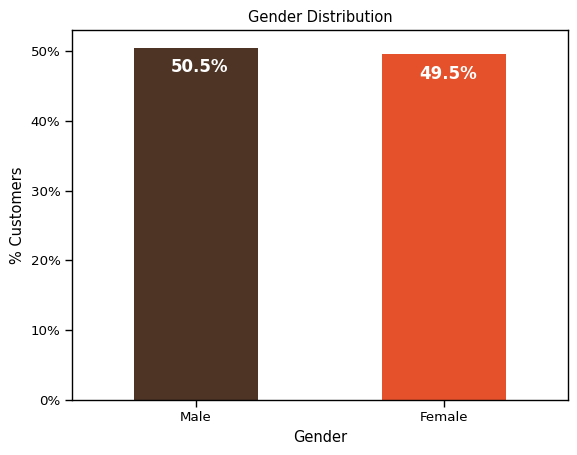

In [704]:
# Graph for Gender Vs Percentage of Customers
import matplotlib.ticker as mtick
colors = ['#4D3425','#E4512B']
ax = (df['gender'].value_counts()*100.0 /len(df)).plot(kind='bar',
                                                                           stacked = True,
                                                                          rot = 0,
                                                                          color = colors)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% Customers')
ax.set_xlabel('Gender')
ax.set_ylabel('% Customers')
ax.set_title('Gender Distribution')

totals = []

for i in ax.patches:
    totals.append(i.get_width())


total = sum(totals)

for i in ax.patches:

    ax.text(i.get_x()+.15, i.get_height()-3.5, \
            str(round((i.get_height()/total), 1))+'%',
            fontsize=12,
            color='white',
           weight = 'bold')

Text(0.5, 1.0, '% of Senior Citizens')

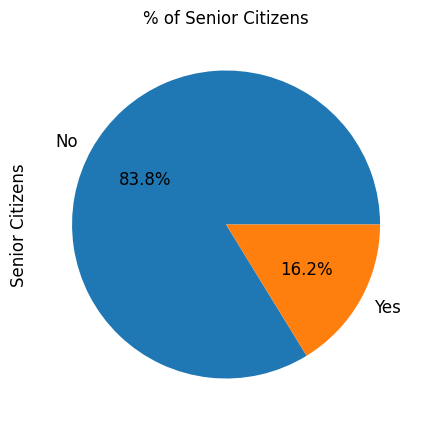

In [705]:
# Percentage of Senior Citizens
ax = (df['SeniorCitizen'].value_counts()*100.0 /len(df))\
.plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 )
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Senior Citizens',fontsize = 12)
ax.set_title('% of Senior Citizens', fontsize = 12)

In [706]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

services = ['PhoneService','MultipleLines','InternetService','OnlineSecurity',
           'OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']

fig = make_subplots(rows=3, cols=3, subplot_titles=services)

colors = ['#FF6F61', '#6B5B95', '#88B04B', '#F7CAC9', '#92A8D1',
          '#955251', '#B565A7', '#009B77', '#DD4124']

for i, col in enumerate(services):
    row = i // 3 + 1
    col_pos = i % 3 + 1

    counts = df[col].value_counts()

    fig.add_trace(
        go.Bar(
            x=counts.index,
            y=counts.values,
            marker_color=colors[i],
            text=counts.values,
            textposition='outside',
            showlegend=False
        ),
        row=row, col=col_pos
    )

fig.update_layout(
    height=1500,
    width=1100,
    title_text="Service-wise Distribution",
    title_x=0.5
)

fig.update_xaxes(tickangle=20)

fig.show()

In [707]:
fig = px.histogram(
    df,
    x='tenure',
    nbins=int(180/5),
    title='Distribution of Customer Tenure',
    color_discrete_sequence=['darkblue']
)

fig.update_layout(template='plotly_dark')
fig.show()

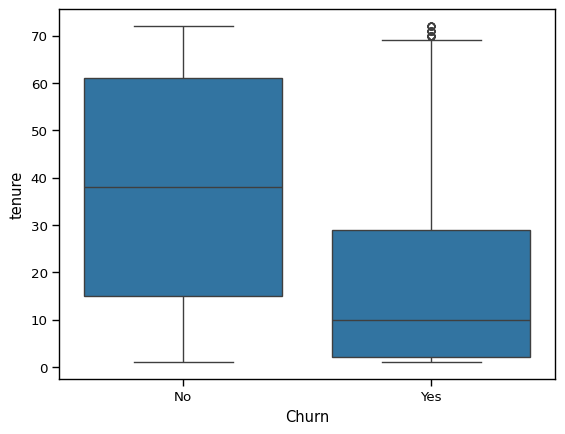

In [708]:
sns.boxplot(x = df.Churn, y = df.tenure)
plt.show()

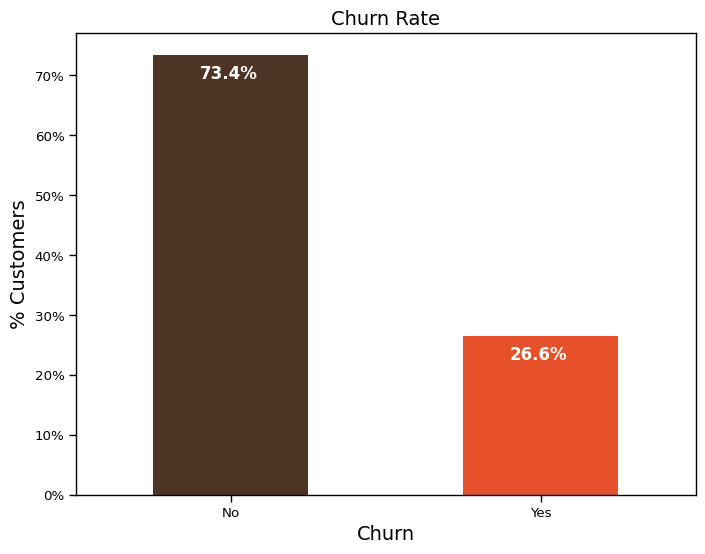

In [709]:
colors = ['#4D3425','#E4512B']
ax = (df['Churn'].value_counts()*100.0 /len(df)).plot(kind='bar',
                                                                           stacked = True,
                                                                          rot = 0,
                                                                          color = colors,
                                                                         figsize = (8,6))
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% Customers',size = 14)
ax.set_xlabel('Churn',size = 14)
ax.set_title('Churn Rate', size = 14)


totals = []

for i in ax.patches:
    totals.append(i.get_width())


total = sum(totals)

for i in ax.patches:

    ax.text(i.get_x()+.15, i.get_height()-4.0, \
            str(round((i.get_height()/total), 1))+'%',
            fontsize=12,
            color='white',
           weight = 'bold')

In [710]:
c_labels = ['No', 'Yes']
male_data = df[df['gender'] == 'Male']['Churn'].value_counts()
female_data = df[df['gender'] == 'Female']['Churn'].value_counts()
fig = make_subplots(rows=1, cols=2, specs=[[{'type':'domain'}, {'type':'domain'}]])

# Male donut
fig.add_trace(
    go.Pie(
        labels=c_labels,
        values=[male_data.get('No', 0), male_data.get('Yes', 0)],
        name="Male"
    ),
    1, 1
)

# Female donut
fig.add_trace(
    go.Pie(
        labels=c_labels,
        values=[female_data.get('No', 0), female_data.get('Yes', 0)],
        name="Female"
    ),
    1, 2
)

# Donut styling
fig.update_traces(
    hole=0.4,
    hoverinfo="label+percent+name",
    textinfo="percent+label"
)

# Layout
fig.update_layout(
    title_text="Churn Distribution by Gender",
    annotations=[
        dict(text='Male', x=0.18, y=0.5, font_size=18, showarrow=False),
        dict(text='Female', x=0.82, y=0.5, font_size=18, showarrow=False)
    ]
)

fig.show()

In [711]:
fig = px.histogram(df, x="Churn", color="TechSupport",barmode="group",  title="<b>Chrun distribution w.r.t. TechSupport</b>")
fig.update_layout(width=700, height=500, bargap=0.1)
fig.show()

In [712]:
# Get counts
no_churn = df[df['Churn'] == 'No']['PaymentMethod'].value_counts()
yes_churn = df[df['Churn'] == 'Yes']['PaymentMethod'].value_counts()

labels = df['PaymentMethod'].unique()

# Create subplots
fig = make_subplots(rows=1, cols=2, specs=[[{'type':'domain'}, {'type':'domain'}]])

# Churn = No
fig.add_trace(
    go.Pie(
        labels=no_churn.index,
        values=no_churn.values,
        name="No Churn"
    ),
    1, 1
)

# Churn = Yes
fig.add_trace(
    go.Pie(
        labels=yes_churn.index,
        values=yes_churn.values,
        name="Churn"
    ),
    1, 2
)

# Styling
fig.update_traces(
    hole=0.4,
    textinfo='percent+label',
    hoverinfo='label+percent+name'
)

# Layout
fig.update_layout(
    title_text="Payment Method Distribution w.r.t Churn",
    annotations=[
        dict(text='No Churn', x=0.18, y=0.5, font_size=16, showarrow=False),
        dict(text='Churn', x=0.82, y=0.5, font_size=16, showarrow=False)
    ]
)

fig.show()

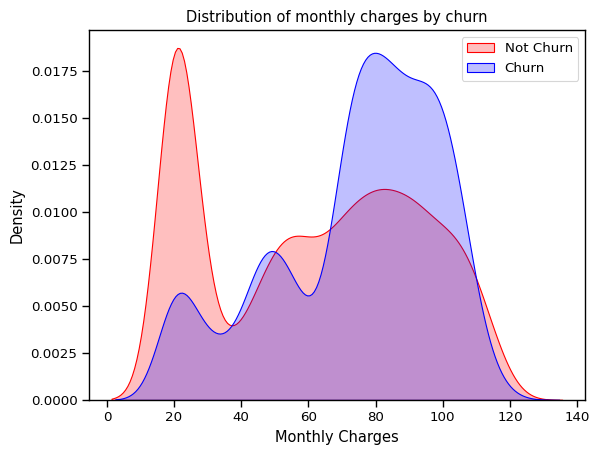

In [713]:
sns.set_context("paper",font_scale=1.1)
ax = sns.kdeplot(df.MonthlyCharges[(df["Churn"] == 'No') ],
                color="Red", shade = True);
ax = sns.kdeplot(df.MonthlyCharges[(df["Churn"] == 'Yes') ],
                ax =ax, color="Blue", shade= True);
ax.legend(["Not Churn","Churn"],loc='upper right');
ax.set_ylabel('Density');
ax.set_xlabel('Monthly Charges');
ax.set_title('Distribution of monthly charges by churn');

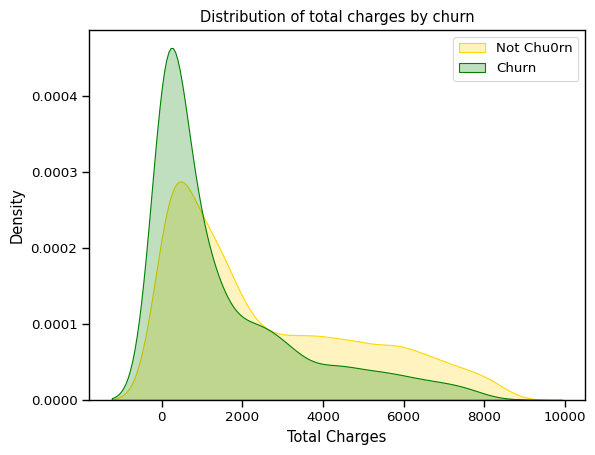

In [714]:
ax = sns.kdeplot(df.TotalCharges[(df["Churn"] == 'No') ],
                color="Gold", shade = True);
ax = sns.kdeplot(df.TotalCharges[(df["Churn"] == 'Yes') ],
                ax =ax, color="Green", shade= True);
ax.legend(["Not Chu0rn","Churn"],loc='upper right');
ax.set_ylabel('Density');
ax.set_xlabel('Total Charges');
ax.set_title('Distribution of total charges by churn');

In [715]:



corr = df.apply(lambda x: pd.factorize(x)[0]).corr()

fig = px.imshow(
    corr,
    text_auto=".2f",
    color_continuous_scale='RdBu_r',  # better contrast
    zmin=-1,
    zmax=1,
    title="Feature Correlation Heatmap"
)

fig.update_layout(
    width=900,
    height=800
)

fig.show()

# Data Preprocessing

In [716]:
import pandas as pd

def object_to_onehot(df, target_col='Churn'):
  object_cols = df.select_dtypes(include='object').columns
  object_cols = object_cols.drop(target_col)
  df_encoded = pd.get_dummies(df, columns=object_cols, drop_first=True)
  return df_encoded








In [717]:
df_new = object_to_onehot(df)
df_new.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,No,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,No,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,Yes,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,No,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,Yes,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [718]:
df_new['Churn'] = df_new['Churn'].map({'Yes': 1, 'No': 0})

In [719]:
df_new

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,0,24,84.80,1990.50,0,True,True,True,True,False,...,False,True,False,True,True,False,True,False,False,True
7028,0,72,103.20,7362.90,0,False,True,True,True,False,...,False,True,False,True,True,False,True,True,False,False
7029,0,11,29.60,346.45,0,False,True,True,False,True,...,False,False,False,False,False,False,True,False,True,False
7030,1,4,74.40,306.60,1,True,True,False,True,False,...,False,False,False,False,False,False,True,False,False,True


In [720]:
plt.figure(figsize=(14,7))
df_new.corr()['Churn'].sort_values(ascending = False)

,Churn
Churn,1.000000
InternetService_Fiber optic,0.307463
PaymentMethod_Electronic check,0.301455
MonthlyCharges,0.192858
PaperlessBilling_Yes,0.191454
SeniorCitizen,0.150541
StreamingTV_Yes,0.063254
StreamingMovies_Yes,0.060860
MultipleLines_Yes,0.040033
PhoneService_Yes,0.011691


<Figure size 1400x700 with 0 Axes>

In [721]:
df = df_new

In [722]:
X = df.drop(columns = ['Churn'])
y = df['Churn'].values

In [723]:
X

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,0,24,84.80,1990.50,True,True,True,True,False,True,...,False,True,False,True,True,False,True,False,False,True
7028,0,72,103.20,7362.90,False,True,True,True,False,True,...,False,True,False,True,True,False,True,True,False,False
7029,0,11,29.60,346.45,False,True,True,False,True,False,...,False,False,False,False,False,False,True,False,True,False
7030,1,4,74.40,306.60,True,True,False,True,False,True,...,False,False,False,False,False,False,True,False,False,True


In [724]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.30, random_state = 42, stratify=y)

In [725]:
num_cols = ["tenure", 'MonthlyCharges', 'TotalCharges']
scaler= StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Machine Learning Model Evaluations and Predictions

LogisticRegression
Model Training Performance
Accuracy: 0.8061611374407583
Precision: 0.7537891494617426
Recall: 0.7298395031467602
F1 Score: 0.7398967712767961
Classification matrix               precision    recall  f1-score   support

           0       0.85      0.89      0.87      1549
           1       0.66      0.57      0.61       561

    accuracy                           0.81      2110
   macro avg       0.75      0.73      0.74      2110
weighted avg       0.80      0.81      0.80      2110



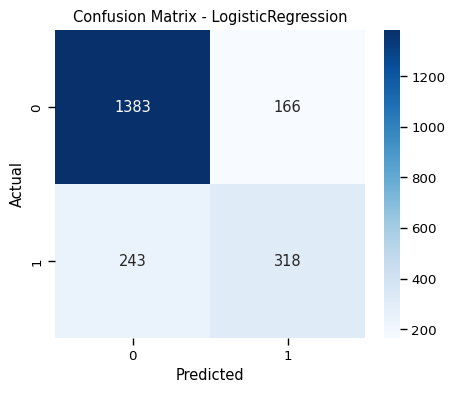



DecisionTreeClassifier
Model Training Performance
Accuracy: 0.7033175355450237
Precision: 0.6288023065551025
Recall: 0.6370552446578726
F1 Score: 0.63216627735096
Classification matrix               precision    recall  f1-score   support

           0       0.81      0.78      0.79      1549
           1       0.45      0.50      0.47       561

    accuracy                           0.70      2110
   macro avg       0.63      0.64      0.63      2110
weighted avg       0.71      0.70      0.71      2110



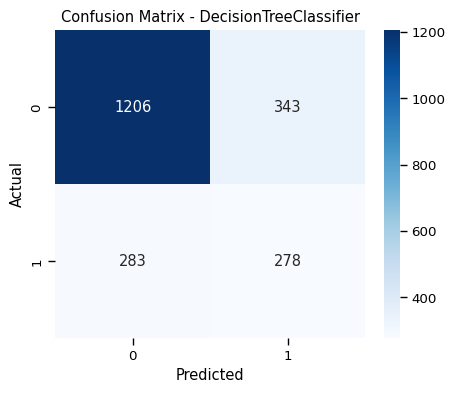



RandomForestClassifier
Model Training Performance
Accuracy: 0.7848341232227488
Precision: 0.7260840594640021
Recall: 0.6823423541609848
F1 Score: 0.6970082274693479
Classification matrix               precision    recall  f1-score   support

           0       0.82      0.90      0.86      1549
           1       0.63      0.46      0.53       561

    accuracy                           0.78      2110
   macro avg       0.73      0.68      0.70      2110
weighted avg       0.77      0.78      0.77      2110



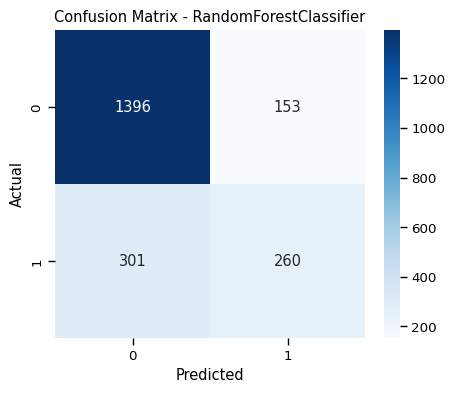



KNeighborsClassifier
Model Training Performance
Accuracy: 0.7606635071090048
Precision: 0.694312118902439
Recall: 0.6971463390215527
F1 Score: 0.6956853897286144
Classification matrix               precision    recall  f1-score   support

           0       0.84      0.83      0.84      1549
           1       0.55      0.56      0.56       561

    accuracy                           0.76      2110
   macro avg       0.69      0.70      0.70      2110
weighted avg       0.76      0.76      0.76      2110



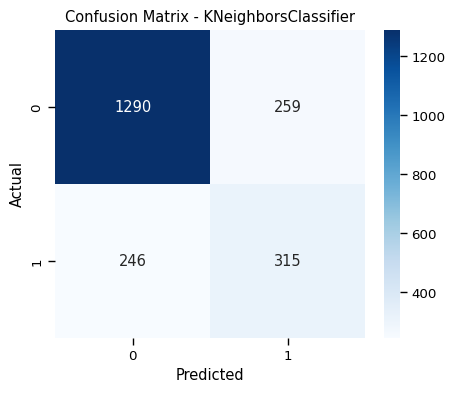



SVC
Model Training Performance
Accuracy: 0.795260663507109
Precision: 0.7440357175815049
Recall: 0.6917176166786921
F1 Score: 0.7087423312883436
Classification matrix               precision    recall  f1-score   support

           0       0.83      0.91      0.87      1549
           1       0.66      0.47      0.55       561

    accuracy                           0.80      2110
   macro avg       0.74      0.69      0.71      2110
weighted avg       0.78      0.80      0.78      2110



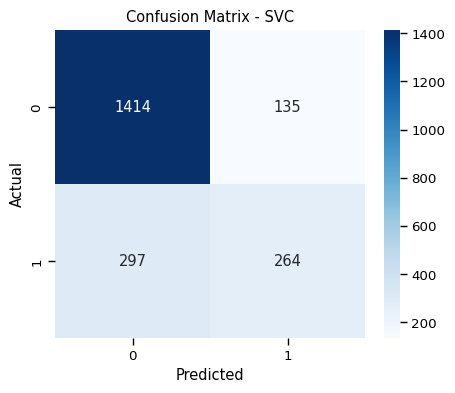



lda
Model Training Performance
Accuracy: 0.795734597156398
Precision: 0.7385189962244756
Recall: 0.7221696707323108
F1 Score: 0.729348303237279
Classification matrix               precision    recall  f1-score   support

           0       0.85      0.88      0.86      1549
           1       0.63      0.57      0.60       561

    accuracy                           0.80      2110
   macro avg       0.74      0.72      0.73      2110
weighted avg       0.79      0.80      0.79      2110



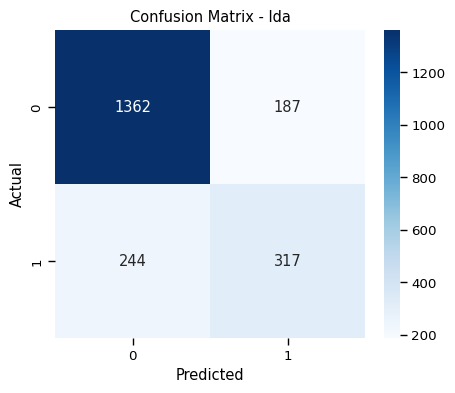

In [726]:
def evaluate_classification_model(true, predicted, prob_predictions=None):
    # Accuracy
    accuracy = accuracy_score(true, predicted)

    # Precision
    precision = precision_score(true, predicted, average='macro')

    # Recall
    recall = recall_score(true, predicted, average='macro')

    # F1-Score
    f1 = f1_score(true, predicted, average='macro')

    # Confusion Matrix
    cm = confusion_matrix(true, predicted)

    classification_report_str = metrics.classification_report(true, predicted)

    return accuracy, precision, recall, f1, cm, classification_report_str

models = {
    "LogisticRegression": LogisticRegression(),
    "DecisionTreeClassifier": DecisionTreeClassifier(),
    "RandomForestClassifier": RandomForestClassifier(),
    "KNeighborsClassifier": KNeighborsClassifier(n_neighbors=5),
    "SVC": SVC(),
    "lda": LinearDiscriminantAnalysis()
}

train_model_list = []
model_list = []
accuracy_list = []

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    accuracy, precision, recall, f1, cm, classification_report = evaluate_classification_model(y_test, y_pred)

    print(name)
    model_list.append(name)

    print("Model Training Performance")
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)
    print("Classification matrix", classification_report) # This will now print the string report

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    accuracy_list.append(accuracy)

    print("="*35)
    print("\n")

In [727]:
model_results = pd.DataFrame({
    "Model": model_list,
    "Accuracy": accuracy_list
})

model_results = model_results.sort_values(by="Accuracy", ascending=False)

model_results.reset_index(drop=True, inplace=True)

model_results

,Model,Accuracy
0,LogisticRegression,0.806161
1,lda,0.795735
2,SVC,0.795261
3,RandomForestClassifier,0.784834
4,KNeighborsClassifier,0.760664
5,DecisionTreeClassifier,0.703318


In [728]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(256, 128, 64, 32, 16),
    activation='relu',
    solver='adam',
    learning_rate='adaptive',
    max_iter=1200,
    early_stopping=True,
    random_state=42
)

mlp_model.fit(X_train, y_train)

y_pred = mlp_model.predict(X_test)

In [729]:
accuracy, precision, recall, f1, cm ,classification_report= evaluate_classification_model(y_test, y_pred)

print("MLP Classifier Performance")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Confusion Matrix:\n", cm)
print("Classification Report:\n", classification_report)

MLP Classifier Performance
Accuracy: 0.7909952606635071
Precision: 0.7476877773630293
Recall: 0.6649364951685235
F1 Score: 0.6847305160978833
Confusion Matrix:
 [[1447  102]
 [ 339  222]]
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.93      0.87      1549
           1       0.69      0.40      0.50       561

    accuracy                           0.79      2110
   macro avg       0.75      0.66      0.68      2110
weighted avg       0.78      0.79      0.77      2110



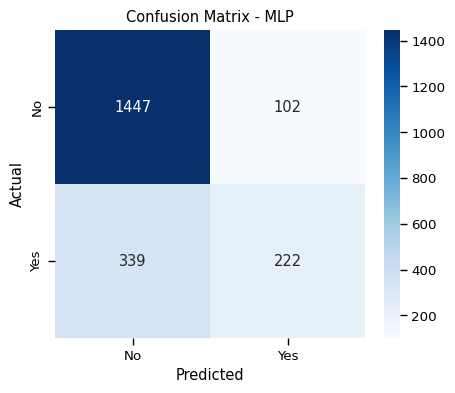

In [730]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'],
            yticklabels=['No','Yes'])

plt.title("Confusion Matrix - MLP")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [731]:
new_row = pd.DataFrame({
    "Model": ["NeuralNetwork"],
    "Accuracy": [accuracy]
})

model_results = pd.concat([model_results, new_row], ignore_index=True)

model_results = model_results.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

model_results

,Model,Accuracy
0,LogisticRegression,0.806161
1,lda,0.795735
2,SVC,0.795261
3,NeuralNetwork,0.790995
4,RandomForestClassifier,0.784834
5,KNeighborsClassifier,0.760664
6,DecisionTreeClassifier,0.703318


In [732]:
import plotly.express as px

fig = px.bar(
    model_results,
    x="Model",
    y="Accuracy",
    title="Model Accuracy Comparison",
    color="Accuracy",
    color_continuous_scale="viridis"
)


fig.update_layout(xaxis=dict(categoryorder='total descending'))

fig.show()

In [733]:
pca = PCA()


pca.fit(X_train)


X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)


explained_variance = pca.explained_variance_ratio_


cumulative_variance = np.cumsum(explained_variance)

# Create DataFrame
explained_variance_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(explained_variance))],
    'Explained Variance Ratio': explained_variance,
    'Cumulative Variance': cumulative_variance
})

print(explained_variance_df)

   Principal Component  Explained Variance Ratio  Cumulative Variance
0                  PC1              3.924850e-01             0.392485
1                  PC2              1.872038e-01             0.579689
2                  PC3              6.009499e-02             0.639784
3                  PC4              3.501739e-02             0.674801
4                  PC5              3.365385e-02             0.708455
5                  PC6              3.066591e-02             0.739121
6                  PC7              2.832222e-02             0.767443
7                  PC8              2.586729e-02             0.793310
8                  PC9              2.523125e-02             0.818542
9                 PC10              2.251513e-02             0.841057
10                PC11              1.937793e-02             0.860435
11                PC12              1.880373e-02             0.879239
12                PC13              1.768024e-02             0.896919
13                PC

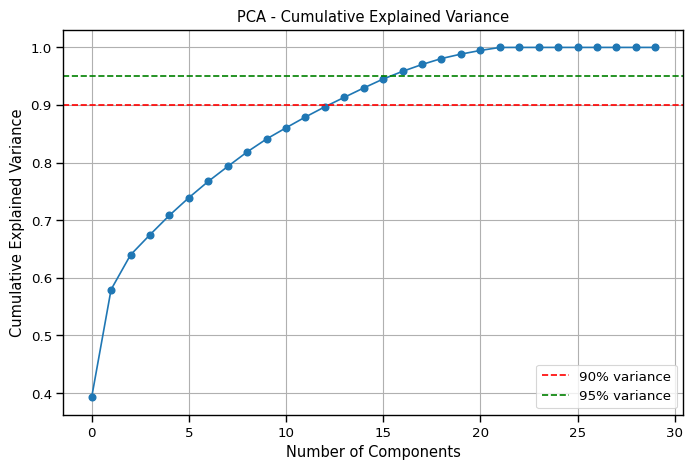

In [734]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(cumulative_variance, marker='o')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% variance')
plt.axhline(y=0.95, color='g', linestyle='--', label='95% variance')

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")

plt.legend()
plt.grid()
plt.show()

In [735]:
pca = PCA(n_components=15)

# Step 2: Fit on training data
X_train = pca.fit_transform(X_train)

# Step 3: Transform test data
X_test = pca.transform(X_test)


LogisticRegression
Model Training Performance
Accuracy: 0.7985781990521327
Precision: 0.744575858179574
Recall: 0.7115999166847912
F1 Score: 0.7243377419825856
Classification matrix               precision    recall  f1-score   support

           0       0.84      0.90      0.87      1549
           1       0.65      0.53      0.58       561

    accuracy                           0.80      2110
   macro avg       0.74      0.71      0.72      2110
weighted avg       0.79      0.80      0.79      2110



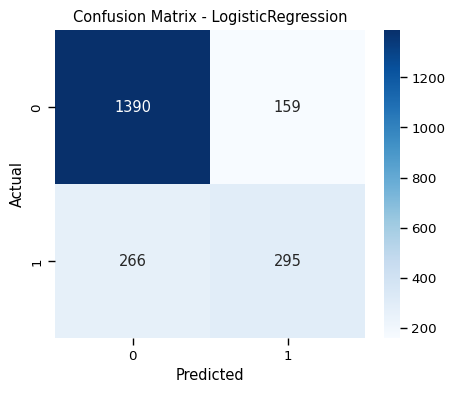



DecisionTreeClassifier
Model Training Performance
Accuracy: 0.7227488151658767
Precision: 0.645247859954309
Recall: 0.6457417757877257
F1 Score: 0.6454927302100162
Classification matrix               precision    recall  f1-score   support

           0       0.81      0.81      0.81      1549
           1       0.48      0.48      0.48       561

    accuracy                           0.72      2110
   macro avg       0.65      0.65      0.65      2110
weighted avg       0.72      0.72      0.72      2110



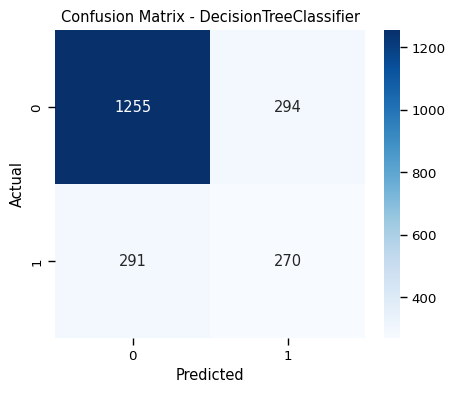



RandomForestClassifier
Model Training Performance
Accuracy: 0.7786729857819905
Precision: 0.7164347202295552
Recall: 0.6735982849034914
F1 Score: 0.6876579944268679
Classification matrix               precision    recall  f1-score   support

           0       0.82      0.90      0.86      1549
           1       0.61      0.45      0.52       561

    accuracy                           0.78      2110
   macro avg       0.72      0.67      0.69      2110
weighted avg       0.76      0.78      0.77      2110



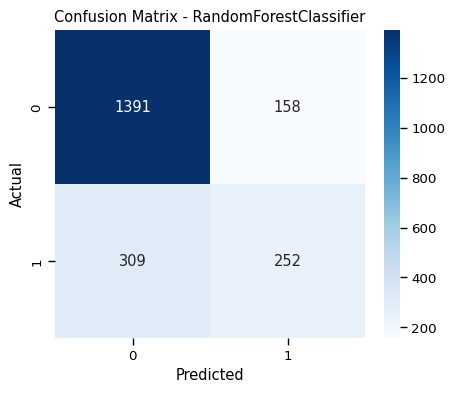



KNeighborsClassifier
Model Training Performance
Accuracy: 0.7691943127962085
Precision: 0.7046414709167139
Recall: 0.7057989226560981
F1 Score: 0.7052135069858922
Classification matrix               precision    recall  f1-score   support

           0       0.84      0.84      0.84      1549
           1       0.57      0.57      0.57       561

    accuracy                           0.77      2110
   macro avg       0.70      0.71      0.71      2110
weighted avg       0.77      0.77      0.77      2110



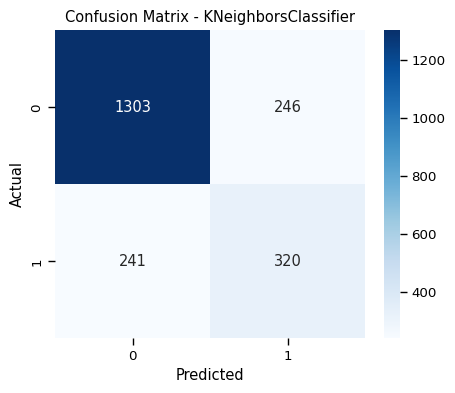



SVC
Model Training Performance
Accuracy: 0.795260663507109
Precision: 0.7440357175815049
Recall: 0.6917176166786921
F1 Score: 0.7087423312883436
Classification matrix               precision    recall  f1-score   support

           0       0.83      0.91      0.87      1549
           1       0.66      0.47      0.55       561

    accuracy                           0.80      2110
   macro avg       0.74      0.69      0.71      2110
weighted avg       0.78      0.80      0.78      2110



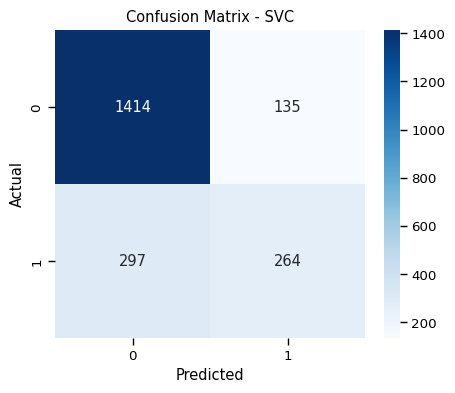



lda
Model Training Performance
Accuracy: 0.7976303317535545
Precision: 0.741223602484472
Recall: 0.7234608263165587
F1 Score: 0.7311900621147662
Classification matrix               precision    recall  f1-score   support

           0       0.85      0.88      0.86      1549
           1       0.63      0.57      0.60       561

    accuracy                           0.80      2110
   macro avg       0.74      0.72      0.73      2110
weighted avg       0.79      0.80      0.79      2110



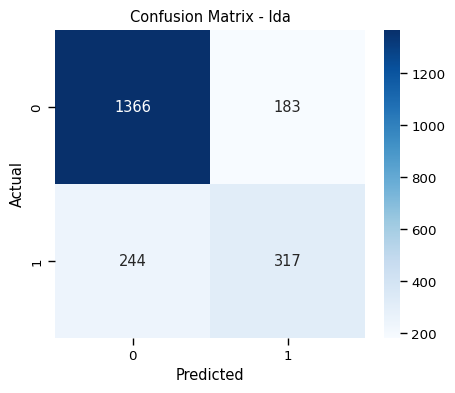

In [736]:
models = {
    "LogisticRegression": LogisticRegression(),
    "DecisionTreeClassifier": DecisionTreeClassifier(),
    "RandomForestClassifier": RandomForestClassifier(),
    "KNeighborsClassifier": KNeighborsClassifier(n_neighbors=5),
    "SVC": SVC(),
    "lda": LinearDiscriminantAnalysis()
}

train_model_list = []
model_list = []
accuracy_list = []

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Evaluation
    accuracy, precision, recall, f1, cm ,classification_report= evaluate_classification_model(y_test, y_pred)

    print(name)
    model_list.append(name)

    print("Model Training Performance")
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)
    print("Classification matrix",classification_report)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    accuracy_list.append(accuracy)

    print("="*35)
    print("\n")

In [737]:

# After PCA
model_results_pca = pd.DataFrame({
    "Model": model_list,
    "Accuracy": accuracy_list
})

# Sort by accuracy (descending)
model_results_pca = model_results_pca.sort_values(by="Accuracy", ascending=False)

# Reset index for clean display
model_results_pca.reset_index(drop=True, inplace=True)

model_results_pca

,Model,Accuracy
0,LogisticRegression,0.798578
1,lda,0.797630
2,SVC,0.795261
3,RandomForestClassifier,0.778673
4,KNeighborsClassifier,0.769194
5,DecisionTreeClassifier,0.722749


In [738]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=( 64, 32, 16),
    activation='relu',
    solver='adam',
    learning_rate='adaptive',
    max_iter=1200,
    early_stopping=True,
    random_state=42
)

mlp_model.fit(X_train, y_train)

y_pred = mlp_model.predict(X_test)

In [739]:
accuracy, precision, recall, f1, cm ,classification_report= evaluate_classification_model(y_test, y_pred)

print("MLP Classifier Performance")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Confusion Matrix:\n", cm)
print("Classification Report:\n", classification_report)

MLP Classifier Performance
Accuracy: 0.7914691943127962
Precision: 0.7340061750937883
Recall: 0.7027787463362598
F1 Score: 0.7148003971413686
Confusion Matrix:
 [[1382  167]
 [ 273  288]]
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.89      0.86      1549
           1       0.63      0.51      0.57       561

    accuracy                           0.79      2110
   macro avg       0.73      0.70      0.71      2110
weighted avg       0.78      0.79      0.78      2110



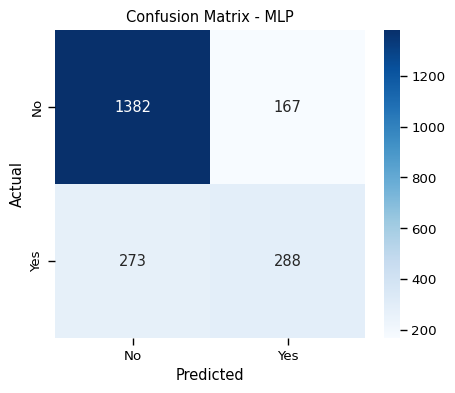

In [740]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'],
            yticklabels=['No','Yes'])

plt.title("Confusion Matrix - MLP")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [741]:

new_model_name = "NeuralNetwork"
new_accuracy = accuracy

# Add new row
model_results_pca.loc[len(model_results_pca)] = [new_model_name, new_accuracy]
model_results_pca = model_results_pca.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

model_results_pca

,Model,Accuracy
0,LogisticRegression,0.798578
1,lda,0.797630
2,SVC,0.795261
3,NeuralNetwork,0.791469
4,RandomForestClassifier,0.778673
5,KNeighborsClassifier,0.769194
6,DecisionTreeClassifier,0.722749


In [742]:
import plotly.express as px

fig = px.bar(
    model_results_pca,
    y="Accuracy",
    x="Model",
    title="Model Accuracy Comparison after PCA",
    color="Accuracy",
    color_continuous_scale="viridis"
)

fig.update_layout(yaxis=dict(categoryorder='total ascending'))

fig.show()

In [743]:

model_results = model_results.rename(columns={"Accuracy": "Accuracy_Before"})
model_results_pca = model_results_pca.rename(columns={"Accuracy": "Accuracy_After"})

# Merge both
comparison_df = pd.merge(
    model_results,
    model_results_pca,
    on="Model"
)

comparison_df

,Model,Accuracy_Before,Accuracy_After
0,LogisticRegression,0.806161,0.798578
1,lda,0.795735,0.797630
2,SVC,0.795261,0.795261
3,NeuralNetwork,0.790995,0.791469
4,RandomForestClassifier,0.784834,0.778673
5,KNeighborsClassifier,0.760664,0.769194
6,DecisionTreeClassifier,0.703318,0.722749


In [744]:
import plotly.graph_objects as go

fig = go.Figure()

# Before PCA
fig.add_trace(go.Bar(
    x=comparison_df["Model"],
    y=comparison_df["Accuracy_Before"],
    name="Before PCA"
))

# After PCA
fig.add_trace(go.Bar(
    x=comparison_df["Model"],
    y=comparison_df["Accuracy_After"],
    name="After PCA"
))

fig.update_layout(
    title="Model Accuracy Comparison (Before vs After PCA)",
    xaxis_title="Model",
    yaxis_title="Accuracy",
    barmode='group'
)

fig.show()